# Practice lab: German Credit's 5 to 1 matrix, then Rohan's 20 to 1

*Week 5, Tuesday, the TA-led lab. Applies the whole day to a real lending book: the confusion matrix, precision and recall, the line from a documented cost matrix, and the transfer to Kalpa Financial's prices. Also searched as: German credit dataset, cost matrix classification, credit risk threshold.*

**The situation.** German Credit is 1,000 loan applicants from a German lender, published with the Statlog project; 300 of them turned out bad. Its documentation ships a cost matrix: classing a bad customer as good is five times worse than classing a good customer as bad. Kalpa Financial Services' twin is Rohan Desai's lending book, where a false approval costs Rs 60,000 and a wrongful rejection Rs 3,000.

**Who needs the answer.** Rohan Desai, head of risk, who will take the line to his credit committee, and Build 2's brief next week, which writes his prices in.

**The questions on the way.** Where does the 5 to 1 matrix put the line? What does the model cost at that line against the two rules that need no model? What happens at Rohan's 20 to 1? Does the answer survive a second seed and a calibration check?

**How to work.** Each TODO cell has a line ending in `= None`. Replace `None`, run it, then run the check cell: PASS when right, NOT YET when off, TODO while still `None`.

| Seat | Their question about this lab |
|---|---|
| Business owner (head of risk) | What does each mistake cost, and which line is cheapest? |
| Product manager | What does an applicant see when we reject someone who would repay? |
| Solution architect | Where does the approval line live, and who may change it? |
| Senior ML engineer | Are the probabilities honest enough for the cost formula? |
| Implementation engineer | How is the line configured and logged for each decision? |
| QA | Does the decision survive a different split? |

**For the TAs.** Expected numbers (seed 42, 300 held-out applicants): line 0.833; approved 128, bad lent 13, good rejected 95; costs 266 at 0.5, 160 at the line, 450 approve all, 210 reject all; Rohan's line 0.952, Rs 690,000 against Rs 630,000 for rejecting everyone. The three commonest wrong answers are in the trainer guide's run sheet. Cut step 6, then step 5, if the lab runs long; never cut steps 1 to 4 or the write-up.

## Step 0: load the book and fit the model

The cell downloads the data once (about 36 KB), then reads the cache. The model is the same logistic pipeline as the week's, on all twenty columns, trained on 70 percent and scored on 300 held-out applicants. Positive means the applicant was good (repaid).

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, MUTED, LIGHT = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#EEEAFB"

# German Credit (Statlog), OpenML credit-g, id 31. scikit-learn caches the download in ~/.cache/c2_datasets.
import pathlib, numpy as np, pandas as pd
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)
credit = fetch_openml(name="credit-g", version=1, as_frame=True, data_home=str(CACHE)).frame
print(credit.shape)
print(credit["class"].value_counts())

def step(label, value, expected, tol=0.002):
    if value is None:
        print(f"TODO     {label}: replace None above, then run this cell again")
    elif abs(float(value) - expected) <= tol * max(1, abs(expected)):
        print(f"PASS  {label} = {value}")
    else:
        print(f"NOT YET  {label} = {value}; check the hint above the cell")

(1000, 21)
class
good    700
bad     300
Name: count, dtype: int64


In [2]:
y = (credit["class"] == "good").astype(int)
X = credit.drop(columns="class")
num = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat = [c for c in X.columns if c not in num]
train_idx, test_idx = train_test_split(credit.index, test_size=0.3, stratify=y, random_state=42)
prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
model = Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))]).fit(X.loc[train_idx], y.loc[train_idx])
p_good = model.predict_proba(X.loc[test_idx])[:, 1]
y_test = y.loc[test_idx].to_numpy()
print(f"test applicants {len(y_test)}, good {y_test.sum()}, bad {(y_test == 0).sum()}, AUC {roc_auc_score(y_test, p_good):.3f}")
print("PASS  1,000 applicants loaded, 300 bad" if len(credit) == 1000 and (credit["class"] == "bad").sum() == 300 else "CHECK load")
print("PASS  300 held-out applicants, 90 bad" if len(y_test) == 300 and (y_test == 0).sum() == 90 else "CHECK split")

def lend_cells(threshold, p=p_good, yy=y_test):
    lend = p >= threshold
    return {"good lent": int((lend & (yy == 1)).sum()), "bad lent": int((lend & (yy == 0)).sum()),
            "good rejected": int((~lend & (yy == 1)).sum()), "bad rejected": int((~lend & (yy == 0)).sum())}

test applicants 300, good 210, bad 90, AUC 0.783
PASS  1,000 applicants loaded, 300 bad
PASS  300 held-out applicants, 90 bad


## Step 1: where does the 5 to 1 matrix put the line?

Lending to a bad applicant costs 5; rejecting a good one costs 1. Write the line on P(good) with the formula from chapter 4: cost of acting wrongly over the sum of the two costs. Acting means lending.

In [3]:
line_5to1 = 5 / (5 + 1)     # cost of lending wrongly / (cost of lending wrongly + cost of rejecting wrongly)
print("your line:", line_5to1)

your line: 0.8333333333333334


In [4]:
step("the 5:1 line on P(good)", line_5to1, 5 / 6)

PASS  the 5:1 line on P(good) = 0.8333333333333334


## Step 2: the four boxes at that line

Use `lend_cells(line)` to count the four boxes on the 300 held-out applicants. Read each one aloud as a sentence about applicants.

In [5]:
boxes = lend_cells(line_5to1)                 # lend_cells(...) at your line
approved = boxes["good lent"] + boxes["bad lent"]
print(boxes, approved)

{'good lent': 115, 'bad lent': 13, 'good rejected': 95, 'bad rejected': 77} 128


In [6]:
expected = lend_cells(5 / 6)
step("approved at the line", approved, expected["good lent"] + expected["bad lent"])
step("bad applicants lent to", None if boxes is None else boxes["bad lent"], expected["bad lent"])

PASS  approved at the line = 128
PASS  bad applicants lent to = 13


## Step 3: what does each rule cost?

Cost in the matrix's units: 5 for every bad applicant lent to, 1 for every good applicant rejected. Compute it for the line, for the default 0.5, for approving everyone and for rejecting everyone.

In [7]:
def cost_5to1(c):
    return 5 * c["bad lent"] + 1 * c["good rejected"]
costs = {"0.5": cost_5to1(lend_cells(0.5)), "5:1 line": cost_5to1(lend_cells(5 / 6)),
         "approve everyone": cost_5to1(lend_cells(0.0)), "reject everyone": cost_5to1(lend_cells(1.01))}
print(costs)

{'0.5': 266, '5:1 line': 160, 'approve everyone': 450, 'reject everyone': 210}


PASS  cost, 0.5 = 266
PASS  cost, 5:1 line = 160
PASS  cost, approve everyone = 450
PASS  cost, reject everyone = 210


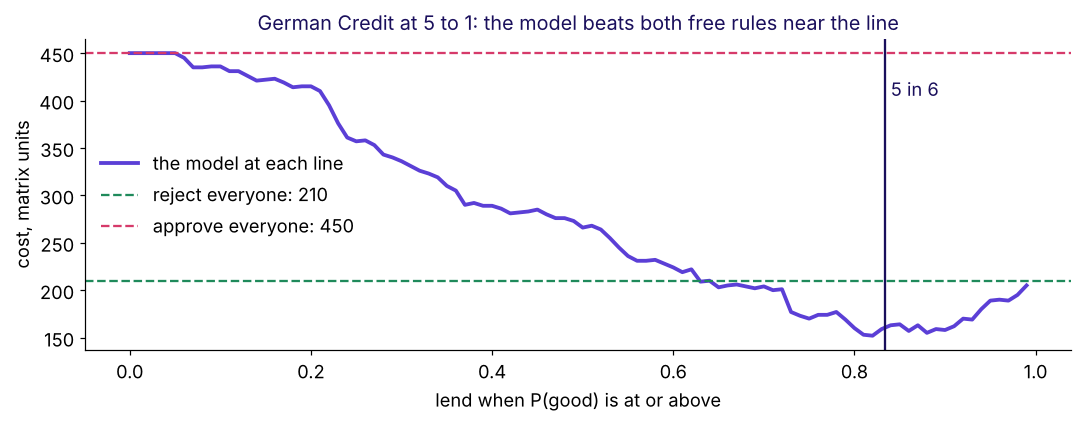

In [8]:
truth = {t: 5 * c["bad lent"] + c["good rejected"] for t, c in
         {"0.5": lend_cells(0.5), "5:1 line": lend_cells(5 / 6), "approve everyone": lend_cells(0.0), "reject everyone": lend_cells(1.01)}.items()}
for k in truth:
    step(f"cost, {k}", costs.get(k), truth[k])
grid = np.round(np.arange(0, 1.0, 0.01), 2)
curve = [5 * lend_cells(t)["bad lent"] + lend_cells(t)["good rejected"] for t in grid]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid, curve, color=VIOLET, lw=2.5, label="the model at each line")
ax.axhline(truth["reject everyone"], color=GREEN, ls="--", label=f"reject everyone: {truth['reject everyone']}")
ax.axhline(truth["approve everyone"], color=ROSE, ls="--", label=f"approve everyone: {truth['approve everyone']}")
ax.axvline(5 / 6, color=INK); ax.text(0.84, max(curve) * 0.9, "5 in 6", color=INK)
ax.set_xlabel("lend when P(good) is at or above"); ax.set_ylabel("cost, matrix units"); ax.legend(frameon=False)
ax.set_title("German Credit at 5 to 1: the model beats both free rules near the line", color=INK); plt.tight_layout(); plt.show()

## Step 4 (assignment): Rohan's 20 to 1, on the same book

At Kalpa Financial a false approval costs Rs 60,000 and a wrongful rejection Rs 3,000. Derive Rohan's line, the bill in rupees at it, and the bill for rejecting everyone. Then write two sentences: why is rejecting everyone so close, and what would you ask Rohan before using this table?

In [9]:
line_rohan = 60000 / 63000            # on P(good)
c = lend_cells(line_rohan)
bill_rohan = 60000 * c["bad lent"] + 3000 * c["good rejected"]
bill_reject_all = 3000 * int(y_test.sum())
print(line_rohan, bill_rohan, bill_reject_all)

0.9523809523809523 690000 630000


In [10]:
c_r = lend_cells(60000 / 63000)
step("Rohan's line", line_rohan, 60000 / 63000)
step("bill at Rohan's line, Rs", bill_rohan, 60000 * c_r["bad lent"] + 3000 * c_r["good rejected"])
step("bill for rejecting everyone, Rs", bill_reject_all, 3000 * int(y_test.sum()))

PASS  Rohan's line = 0.9523809523809523
PASS  bill at Rohan's line, Rs = 690000
PASS  bill for rejecting everyone, Rs = 630000


**Model sentences.** Three applicants in ten default on this book, and at 20 to 1 a single bad approval costs as much as twenty good rejections, so the model must be very sure, and on 700 training rows it is rarely that sure; turning everyone away is close to optimal, and only the very top slice beats it. Before using it on Kalpa's book I would ask Rohan for his default rate and his loss after recoveries, since a 3 percent default book puts far more applicants above the same line.

## Step 5: integration with Week 2: who gets approved, by checking account?

The Week 2 move: a `groupby`. Build a table of the 300 test applicants with their `checking_status`, whether the 5:1 line approves them, and whether they were good. Then group by `checking_status` and report the approval rate and the good rate.

In [11]:
table = pd.DataFrame({"checking_status": X.loc[test_idx, "checking_status"].astype(str).to_numpy(),
                      "approved": (p_good >= 5 / 6).astype(int), "good": y_test})
by_checking = table.groupby("checking_status")[["approved", "good"]].mean().round(3)
print(by_checking)

                 approved   good
checking_status                 
0<=X<200            0.244  0.600
<0                  0.096  0.493
>=200               0.588  0.765
no checking         0.742  0.892


In [12]:
ref = table.groupby("checking_status")[["approved", "good"]].mean()
step("groups in the table", None if by_checking is None else len(by_checking), len(ref))
if by_checking is not None:
    top = by_checking["approved"].idxmax()
    print(f"most approved group: {top}, approval rate {by_checking.loc[top, 'approved']:.2f}")

PASS  groups in the table = 4
most approved group: no checking, approval rate 0.74


## Step 6: QA: does the decision survive a second split and a calibration check?

Try to break the result. Refit with `random_state=7` and check the 5:1 line still beats both free rules. Then bin the held-out predictions into five groups and compare each group's mean P(good) with its observed good rate: the cost formula needs those two to be close.

In [13]:
seed = 7                     # a different seed, for example 7
print("seed:", seed)

seed: 7


seed 7: cost at the line 196, best free rule 210
PASS  the 5:1 line beats both free rules on the second split
     mean_p  observed
bin                  
0     0.266     0.367
1     0.578     0.617
2     0.782     0.717
3     0.901     0.867
4     0.965     0.933


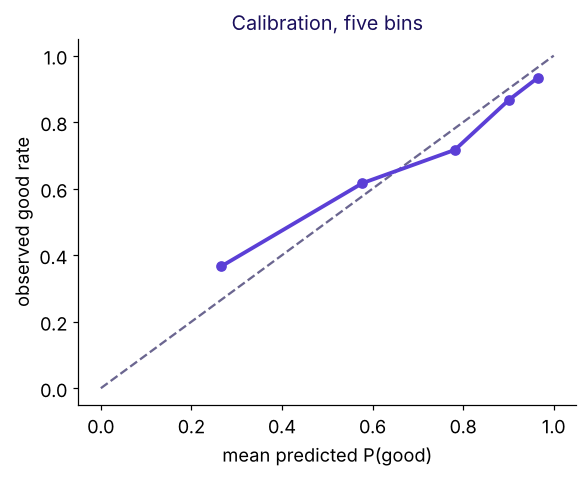

In [14]:
s = 7 if seed is None else seed
tr2, te2 = train_test_split(credit.index, test_size=0.3, stratify=y, random_state=s)
m2 = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
               ("model", LogisticRegression(max_iter=2000))]).fit(X.loc[tr2], y.loc[tr2])
p2, y2 = m2.predict_proba(X.loc[te2])[:, 1], y.loc[te2].to_numpy()
c2 = lend_cells(5 / 6, p2, y2)
model_cost = 5 * c2["bad lent"] + c2["good rejected"]
free = min(5 * int((y2 == 0).sum()), int(y2.sum()))
print(f"seed {s}: cost at the line {model_cost}, best free rule {free}")
print("PASS  the 5:1 line beats both free rules on the second split" if model_cost < free else "CHECK the second split")
bins = pd.qcut(p_good, 5, labels=False)
cal = pd.DataFrame({"bin": bins, "p": p_good, "y": y_test}).groupby("bin").agg(mean_p=("p", "mean"), observed=("y", "mean"))
print(cal.round(3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--"); ax.plot(cal["mean_p"], cal["observed"], "o-", color=VIOLET, lw=2.5)
ax.set_xlabel("mean predicted P(good)"); ax.set_ylabel("observed good rate"); ax.set_title("Calibration, five bins", color=INK)
plt.tight_layout(); plt.show()

## Step 7: the write-up, five lines (model answer)

1. Claim: on German Credit's documented 5 to 1 matrix, lend only when P(good) is at least 5 in 6 (0.833).
2. Evidence: at that line the model approves 128 of 300 held-out applicants, lends to 13 bad ones and turns away 95 good ones, a cost of 160 against 210 for rejecting everyone and 450 for approving everyone.
3. Evidence: on a second split (seed 7) the line still beats both free rules, 196 against 210, a narrower margin; the five calibration bins sit within about 0.1 of the diagonal, and the top bin over-predicts (0.965 against 0.933), which matters most at a high line.
4. Caveat: at Rohan's 20 to 1 the same book is so risky (30 percent bad) that rejecting everyone costs Rs 630,000 against Rs 690,000 at his line; the line is only as good as the prices and the book's default rate.
5. Action: take the 5:1 line to the committee as the method, and ask Rohan for Kalpa's default rate and loss after recoveries before setting his line.